# This Python code generates lifecycle scenarios

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

Matplotlib is building the font cache; this may take a moment.


## Definition of Variables


#### Lifecycle Parameters:

- Years of life (D)
- Working life (T)
- Time interval ($delta$ T)
- Age beginning working period (Start Age)

#### Economic Parameters:

- $r$
- $sigma$
- $lambda$

#### Individual $i$ Preference Parameters:

- Risk aversion parameter ($theta$)
- Time preference parameter ($rho$)

## Baseline Scenario:

Values

In [ ]:
D = 60
T = 45
deltat = 1
age_start = 20
r = 0.02
sigma = 0.2
lambd = 0.04 / sigma
theta = 5
rho = 0.02

## 1. Specification of Human Capital

### 1.1. Defining age

In [ ]:
age = []
for i in range(age_start, age_start + D + 1):
    age.append(i)
print(age)

[20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80]


### 1.2. Specification of Labour Earnings

In [ ]:
Y = []
for i in range(D + 1):
    if age[i] < (age_start + T):
        Y.append(1)
    elif age[i] >= (age_start + T):
        Y.append(0)
print(Y)

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


### 1.3. Specification of Human Capital

[np.float64(29.671517012970046), np.float64(29.260854415920935), np.float64(28.841895884112557), np.float64(28.414473828546015), np.float64(27.97841727470004), np.float64(27.533551794138923), np.float64(27.079699434738824), np.float64(26.61667864950454), np.float64(26.14430422394828), np.float64(25.662387202001412), np.float64(25.17073481042953), np.float64(24.669150381720524), np.float64(24.15743327541504), np.float64(23.635378797847572), np.float64(23.102778120266276), np.float64(22.55941819529868), np.float64(22.005081671729897), np.float64(21.439546807559257), np.float64(20.862587381300518), np.float64(20.273972601490282), np.float64(19.673467014368327), np.float64(19.060830409692958), np.float64(18.435817724653702), np.float64(17.79817894584293), np.float64(17.147659009247164), np.float64(16.483997698218033), np.float64(15.806929539382208), np.float64(15.116183696448449), np.float64(14.411483861869517), np.float64(13.692548146315453), np.float64(12.959088965914106), np.float64(12.

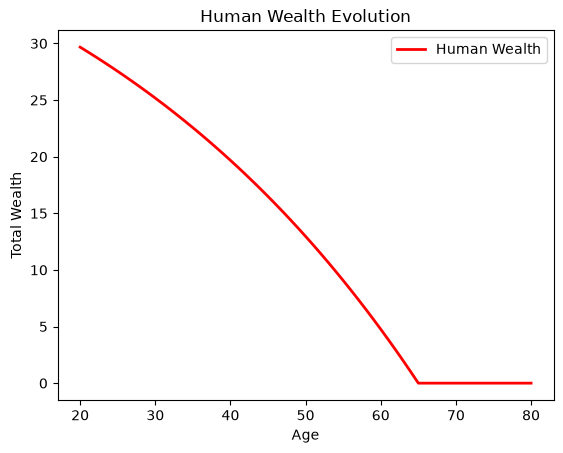

In [8]:
human_capital = []
for i in range(D + 1):
    human_capital.append((1 / r) * (1 - np.exp(-r * max(0, (age_start + T - age[i])))))
print(human_capital)
plt.plot(age, human_capital, color="r", linewidth=2, label="Human Wealth")
plt.xlabel("Age")
plt.ylabel("Total Wealth")
plt.title("Human Wealth Evolution")
plt.legend()
plt.show()

### 1.4. Specification of A and g

In [11]:
A = ((1 - theta) * r - rho) / theta + 0.5 * ((1 - theta) / theta**2) * lambd**2
print(f"A={A}")
g = []
for i in range(D + 1):
    g.append((1 / A) * (np.exp(A * (D - (age[i] - age_start))) - 1))
print(f"g(D-t)={g}")

A=-0.0232
g(D-t)=[np.float64(32.38889431719484), np.float64(32.13741073558279), np.float64(31.88002452917978), np.float64(31.6165971562202), np.float64(31.346986823195074), np.float64(31.071048408529748), np.float64(30.788633384470128), np.float64(30.499589737135516), np.float64(30.203761884694995), np.float64(29.900990593623302), np.float64(29.591112892991152), np.float64(29.273961986743785), np.float64(28.949367163920673), np.float64(28.617153706767922), np.float64(28.277142796693962), np.float64(27.92915141801791), np.float64(27.57299225945879), np.float64(27.208473613312613), np.float64(26.83539927226296), np.float64(26.453568423769624), np.float64(26.062775541978457), np.float64(25.662810277094113), np.float64(25.253457342156356), np.float64(24.83449639715876), np.float64(24.40570193044761), np.float64(23.96684313733707), np.float64(23.517683795875264), np.float64(23.05798213969453), np.float64(22.58749072787718), np.float64(22.10595631176698), np.float64(21.613119698654458), np.f

## 2. Monte Carlo Simulation

#### 2.1. Generating random normal distribution

In [12]:
scenarios = 5000
Z = []
Z = np.random.normal(0, 1, size=(scenarios, D + 1))
print(Z)

[[ 1.46409325 -0.1863725  -0.33933318 ...  2.03674736  1.68926086
  -1.13424535]
 [ 0.74650721  0.20002876 -0.56401001 ...  0.94924946 -1.593403
   0.37915885]
 [ 0.41530978  0.02932337  0.00752993 ... -0.88184008  0.90653791
  -0.66248848]
 ...
 [-1.53747287 -0.27027849 -0.42386074 ...  0.20730568  0.93073057
  -0.26405173]
 [-0.67421146 -1.51725375 -0.05947678 ...  0.33246761  1.48306802
   0.70526626]
 [-0.45377201 -0.53524155 -1.96630243 ... -1.15381805  1.25065595
  -1.05222155]]


#### 2.2. Defining Financial Wealth and Consumption for every simulation in 2.1.

In [13]:
C = np.zeros((scenarios, D + 1))
F = np.zeros((scenarios, D + 1))
fstar = np.zeros((scenarios, D + 1))
fstar_times_F = np.zeros((scenarios, D + 1))

#### Euler approximation (discretization Bias, see VRM slides)

In [14]:
for i in range(D + 1):
    for j in range(scenarios):
        if i == 0:
            F[j][i] = 0
        else:
            F[j][i] = (
                F[j][i - 1]
                + F[j][i - 1] * r * deltat
                + fstar_times_F[j][i - 1] * sigma * lambd * deltat
                + fstar_times_F[j][i - 1] * np.sqrt(deltat) * sigma * Z[j][i]
                + (Y[i - 1] - C[j][i - 1]) * deltat
            )

        C[j][i] = (F[j][i] + human_capital[i]) * g[i] ** (-1)
        fstar_times_F[j][i] = (
            (1 / theta) * (lambd / sigma) * (F[j][i] + human_capital[i])
        )

        if i == 0:
            fstar[j][i] = "NAN"
        else:
            fstar[j][i] = fstar_times_F[j][i] / F[j][i]
print(F)
print(fstar.T)

[[ 0.00000000e+00  1.00072369e-01  2.48298991e-02 ...  2.77778721e+00
   1.62189643e+00 -4.70587849e-02]
 [ 0.00000000e+00  5.58676836e-01  2.07790082e-01 ...  3.29168079e+00
   1.48972972e+00  4.69585171e-02]
 [ 0.00000000e+00  3.56073323e-01  6.87479067e-01 ...  3.54344883e+00
   1.95800995e+00 -1.98628210e-02]
 ...
 [ 0.00000000e+00  4.87647735e-04 -1.72028366e-01 ...  4.06041759e+00
   2.24760160e+00  1.30205310e-02]
 [ 0.00000000e+00 -1.47949826e+00 -1.21738653e+00 ...  2.53815541e+00
   1.46104606e+00  6.51126829e-02]
 [ 0.00000000e+00 -3.13986586e-01 -2.26614508e+00 ...  2.24447662e+00
   1.27112911e+00 -3.27108744e-02]]
[[            nan             nan             nan ...             nan
              nan             nan]
 [ 5.86793878e+01  1.06750555e+01  1.66352972e+01 ...  1.20010163e+04
  -3.75551049e+00 -1.84382831e+01]
 [ 2.32515853e+02  2.79606088e+01  8.59062519e+00 ... -3.33315583e+01
  -4.53833006e+00 -2.34545891e+00]
 ...
 [ 2.00000000e-01  2.00000000e-01  2.0000000

/var/folders/80/77kfxk_12jzglz0947b8yl0w0000gn/T/ipykernel_38996/50880859.py:14: RuntimeWarning: divide by zero encountered in scalar power
  C[j][i] = (F[j][i] + human_capital[i]) * g[i] ** (-1)


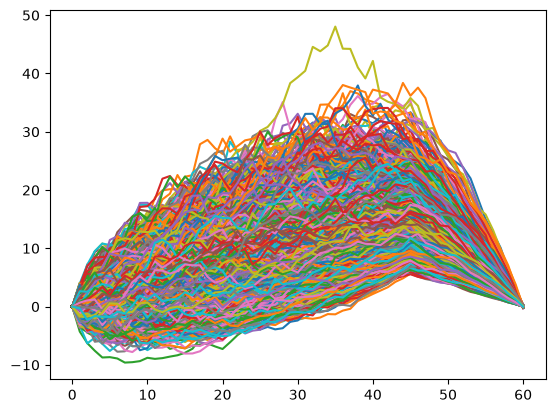

In [15]:
plt.plot(F.T)
plt.show()

In [16]:
mean_F = np.mean(F, axis=0)
print(mean_F)

[ 0.          0.29497022  0.60587632  0.91161326  1.24697521  1.54525075
  1.90541098  2.23188632  2.56191033  2.91203372  3.2363461   3.57684867
  3.89640103  4.24074414  4.58313012  4.90203591  5.23505438  5.54966408
  5.86581668  6.21073176  6.5345494   6.87695422  7.19580405  7.52122321
  7.84693986  8.18915925  8.50685594  8.84570084  9.15543892  9.47732284
  9.82149842 10.15411284 10.48595351 10.80128433 11.11912458 11.4156454
 11.73838639 12.04916334 12.3331944  12.63366072 12.92851022 13.21834857
 13.50175799 13.79281428 14.06738292 14.34212043 13.59838853 12.84702824
 12.06664297 11.24403595 10.40779487  9.53061109  8.622453    7.67911889
  6.70322685  5.69402302  4.64274583  3.55507423  2.42610806  1.25533568
  0.02050928]


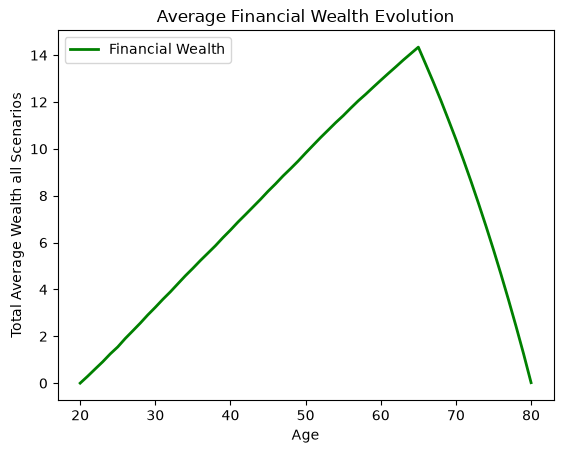

In [17]:
plt.plot(age, mean_F, color="g", linewidth=2, label="Financial Wealth")
plt.xlabel("Age")
plt.ylabel("Total Average Wealth all Scenarios")
plt.title("Average Financial Wealth Evolution")
plt.legend()
plt.show()

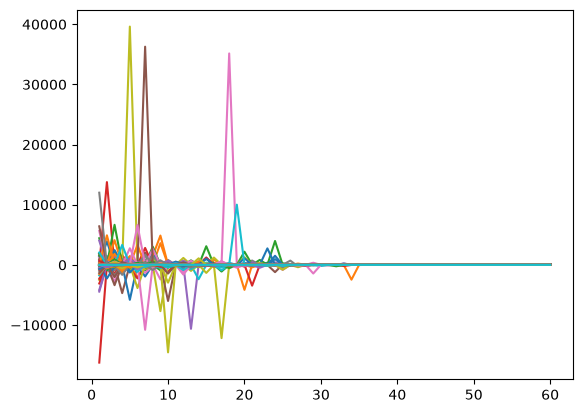

In [18]:
plt.plot(fstar.T)
plt.show()

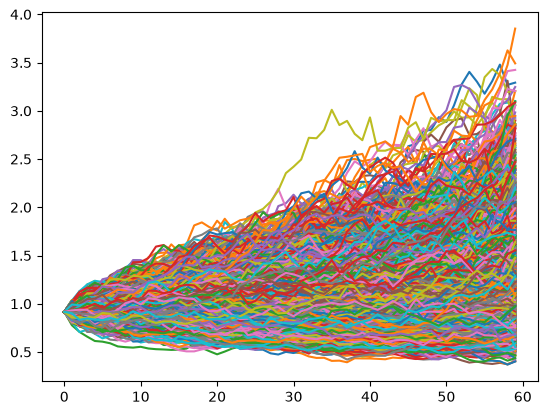

[[0.91610157 0.91610157 0.91610157 ... 0.91610157 0.91610157 0.91610157]
 [0.91360586 0.92787597 0.92157168 ... 0.91050714 0.86445533 0.90072184]
 [0.90548004 0.91121906 0.92626575 ... 0.89930506 0.86651468 0.83361764]
 ...
 [1.42136511 1.68431917 1.81314628 ... 2.07767387 1.29874799 1.14847558]
 [1.64078317 1.50707741 1.98081068 ... 2.27377459 1.47805973 1.28593122]
 [       inf       -inf        inf ...       -inf       -inf        inf]]


In [19]:
plt.plot(C.T)
plt.show()
print(C.T)

In [20]:
mean_C = np.mean(C, axis=0)
print(mean_C)

[0.91610157 0.91967038 0.92370607 0.92755355 0.93231903 0.93588096
 0.94142244 0.94586731 0.95041852 0.95563459 0.95998691 0.96488473
 0.96906555 0.97410536 0.97909143 0.98325415 0.98792818 0.99194138
 0.99601291 1.001177   1.00557273 1.0107149  1.01497476 1.01952549
 1.02412948 1.02947046 1.03385119 1.03920128 1.0433617  1.04812796
 1.05401662 1.05951144 1.06511611 1.07006433 1.07528591 1.07955814
 1.08538731 1.09079243 1.09488556 1.10013429 1.10530644 1.11044737
 1.11547309 1.12138697 1.12653828 1.13213992 1.13757886 1.14473815
 1.15201301 1.15815755 1.16617397 1.1733564  1.18091927 1.18850474
 1.1967653  1.20613196 1.21537516 1.22674194 1.24141452 1.26995388
        nan]


/Users/LaptopvanFrank/Desktop/Cardano/Thesis/Fulcrum/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:132: RuntimeWarning: invalid value encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)


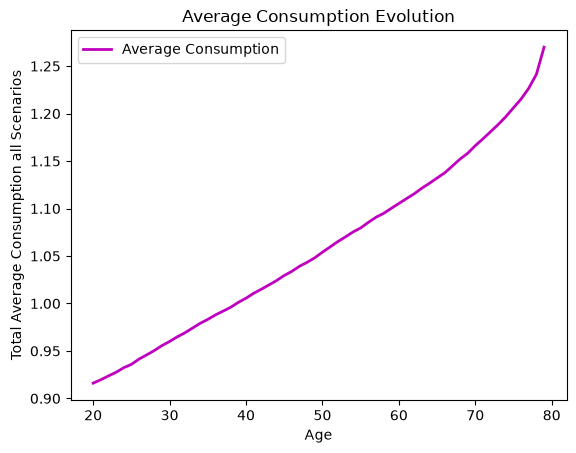

In [21]:
plt.plot(age, mean_C, color="m", linewidth=2, label="Average Consumption")
plt.xlabel("Age")
plt.ylabel("Total Average Consumption all Scenarios")
plt.title("Average Consumption Evolution")
plt.legend()
plt.show()

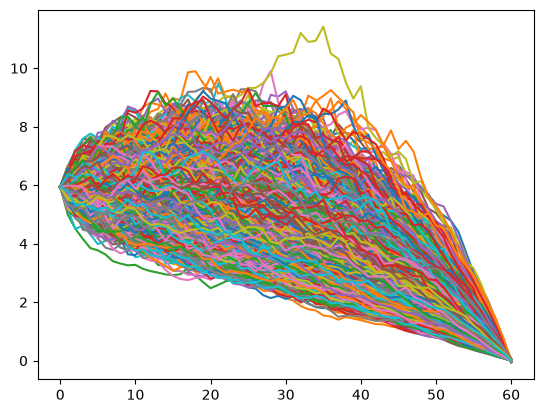

In [22]:
plt.plot(fstar_times_F.T)
plt.show()

In [23]:
mean_fstar_times_F = np.mean(fstar_times_F, axis=0)
print(mean_fstar_times_F)

[5.93430340e+00 5.91116493e+00 5.88955444e+00 5.86521742e+00
 5.84507850e+00 5.81576051e+00 5.79702208e+00 5.76971299e+00
 5.74124291e+00 5.71488418e+00 5.68141618e+00 5.64919981e+00
 5.61076686e+00 5.57522459e+00 5.53718165e+00 5.49229082e+00
 5.44802721e+00 5.39784218e+00 5.34568081e+00 5.29694087e+00
 5.24160328e+00 5.18755693e+00 5.12632435e+00 5.06388043e+00
 4.99891977e+00 4.93463139e+00 4.86275710e+00 4.79237691e+00
 4.71338456e+00 4.63397420e+00 4.55611748e+00 4.47298515e+00
 4.38667484e+00 4.29397826e+00 4.19863694e+00 4.09582155e+00
 3.99497516e+00 3.88839478e+00 3.77305653e+00 3.65752778e+00
 3.53732786e+00 3.41250625e+00 3.28270626e+00 3.15066846e+00
 3.01148985e+00 2.86842409e+00 2.71967771e+00 2.56940565e+00
 2.41332859e+00 2.24880719e+00 2.08155897e+00 1.90612222e+00
 1.72449060e+00 1.53582378e+00 1.34064537e+00 1.13880460e+00
 9.28549165e-01 7.11014847e-01 4.85221613e-01 2.51067135e-01
 4.10185560e-03]


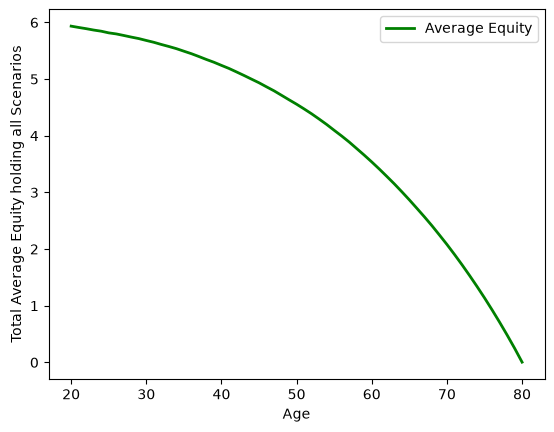

In [26]:
plt.plot(age, mean_fstar_times_F, color="g", linewidth=2, label="Average Equity")
plt.xlabel("Age")
plt.ylabel("Total Average Equity holding all Scenarios")
plt.legend()
plt.show()

### 3. Calculating Welfare

In [32]:
U = sum(
    np.exp(-rho * np.linspace(0, D, D))
    * np.mean((deltat * (1 / (1 - theta)) * C ** (1 - theta)))
)
ce_consumption = (
    U / (sum(np.exp(-rho * np.linspace(0, D, D))) * deltat * (1 / (1 - theta)))
) ** (1 / (1 - theta))

In [33]:
print(U)
print(ce_consumption)

-11.51998317933329
0.9336180507534644


In [29]:
total_wealth = mean_F + human_capital

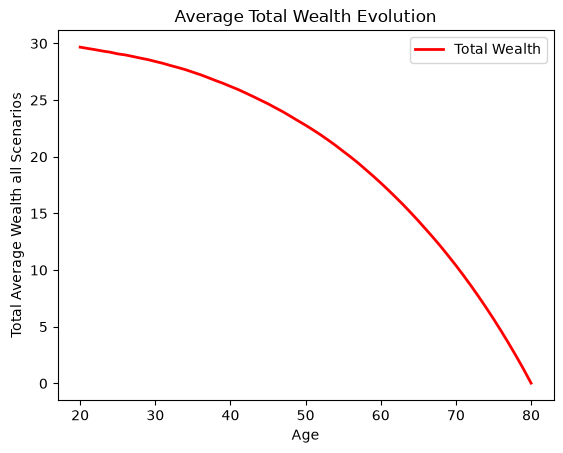

In [30]:
plt.plot(age, total_wealth, color="r", linewidth=2, label="Total Wealth")
plt.xlabel("Age")
plt.ylabel("Total Average Wealth all Scenarios")
plt.title("Average Total Wealth Evolution")
plt.legend()
plt.show()

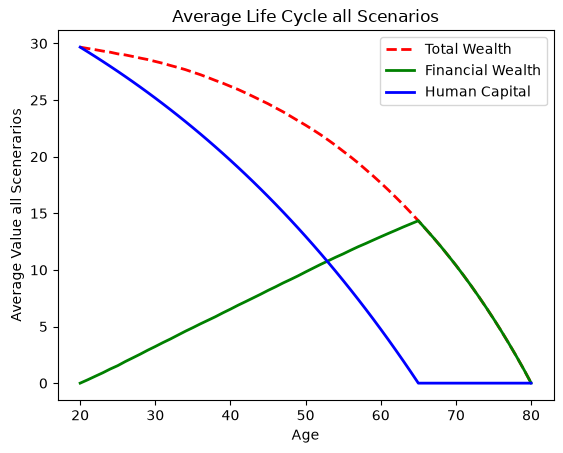

In [31]:
plt.plot(
    age, total_wealth, color="r", linewidth=2, linestyle="--", label="Total Wealth"
)
plt.plot(age, mean_F, color="g", linewidth=2, label="Financial Wealth")
plt.plot(age, human_capital, color="b", linewidth=2, label="Human Capital")
plt.xlabel("Age")
plt.ylabel("Average Value all Scenerarios")
plt.title("Average Life Cycle all Scenarios")
plt.legend()
plt.show()